In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

ESCALA = 1/3                 # se trabaja con los frames reducidos (más rápido)
S_MIN, V_MIN = 150, 60       # saturación/valor mínimos para considerar "rojo"
KERNEL = np.ones((3, 3), np.uint8)

In [2]:
def mascara_roja(frame_bgr, s_min=S_MIN, v_min=V_MIN):
    hsv = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2HSV)
    # El rojo está en los dos extremos del H (0-10 y 170-180), por eso dos rangos
    m = cv2.inRange(hsv, (0, s_min, v_min), (10, 255, 255)) | \
        cv2.inRange(hsv, (170, s_min, v_min), (180, 255, 255))
    # Apertura: elimina líneas finas y ruido (bordes del papel, etc.)
    return cv2.morphologyEx(m, cv2.MORPH_OPEN, KERNEL)

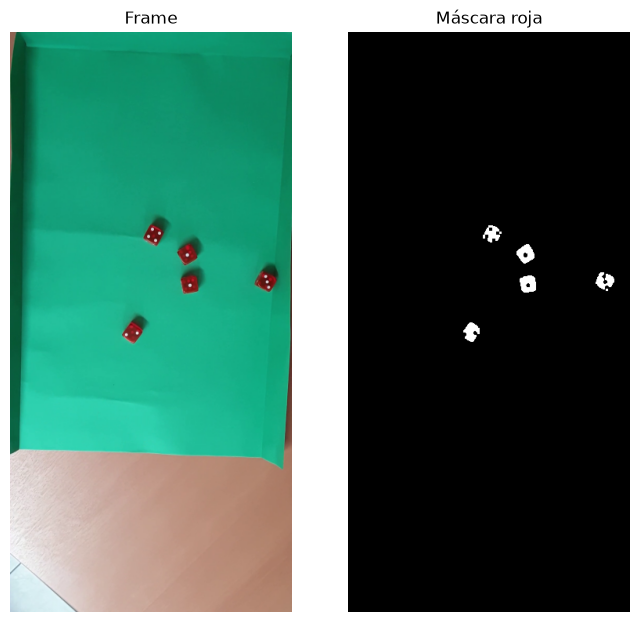

In [3]:
def ver_mascara(path, n_frame):
    cap = cv2.VideoCapture(path)
    cap.set(cv2.CAP_PROP_POS_FRAMES, n_frame)
    ok, frame = cap.read()
    cap.release()
    frame = cv2.resize(frame, None, fx=ESCALA, fy=ESCALA, interpolation=cv2.INTER_AREA)
    m = mascara_roja(frame)

    fig, ax = plt.subplots(1, 2, figsize=(8, 8))
    ax[0].imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)); ax[0].set_title("Frame")
    ax[1].imshow(m, cmap="gray");                         ax[1].set_title("Máscara roja")
    for a in ax: a.axis("off")
    plt.show()

ver_mascara("tirada_1.mp4", 70)

In [4]:
def analizar_video(path):
    cap = cv2.VideoCapture(path)
    prev = None
    cambios, areas = [], []
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        frame = cv2.resize(frame, None, fx=ESCALA, fy=ESCALA, interpolation=cv2.INTER_AREA)
        m = mascara_roja(frame)

        areas.append(int(cv2.countNonZero(m)))                       # píxeles rojos del frame
        if prev is None:
            cambios.append(0)
        else:
            cambios.append(int(cv2.countNonZero(cv2.bitwise_xor(m, prev))))  # píxeles que cambiaron
        prev = m
    cap.release()
    return np.array(cambios), np.array(areas)

resultados = {}
for i in range(1, 5):
    resultados[i] = analizar_video(f"tirada_{i}.mp4")
    print(f"tirada_{i}: {len(resultados[i][0])} frames")

tirada_1: 146 frames
tirada_2: 145 frames
tirada_3: 146 frames
tirada_4: 88 frames


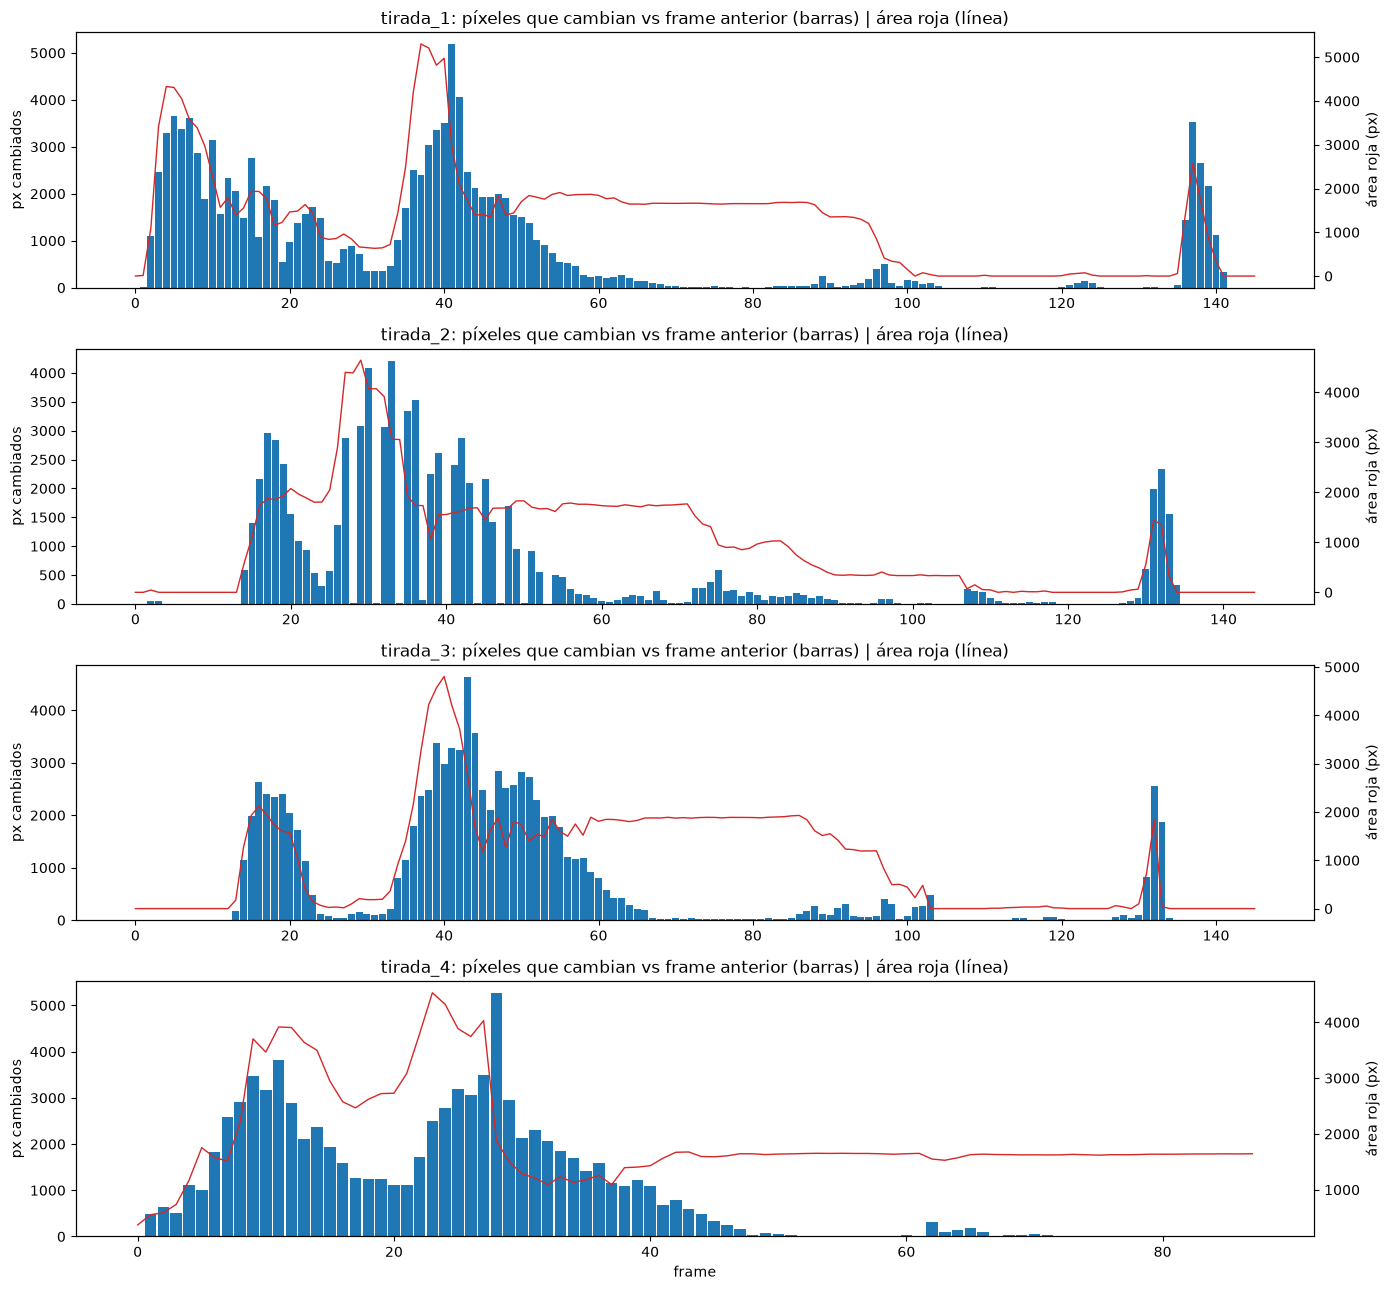

In [5]:
fig, axs = plt.subplots(4, 1, figsize=(14, 13), sharex=False)
for i, ax in zip(range(1, 5), axs):
    cambios, areas = resultados[i]
    ax.bar(range(len(cambios)), cambios, color="tab:blue", width=0.9)
    ax.set_title(f"tirada_{i}: píxeles que cambian vs frame anterior (barras) | área roja (línea)")
    ax.set_ylabel("px cambiados")
    ax2 = ax.twinx()
    ax2.plot(areas, color="tab:red", lw=1)
    ax2.set_ylabel("área roja (px)")
axs[-1].set_xlabel("frame")
plt.tight_layout()
plt.show()

tirada_1: frame 78 | px cambiados = 2 | área roja = 1655
tirada_2: frame 53 | px cambiados = 6 | área roja = 1675
tirada_3: frame 83 | px cambiados = 14 | área roja = 1897
tirada_4: frame 72 | px cambiados = 3 | área roja = 1625


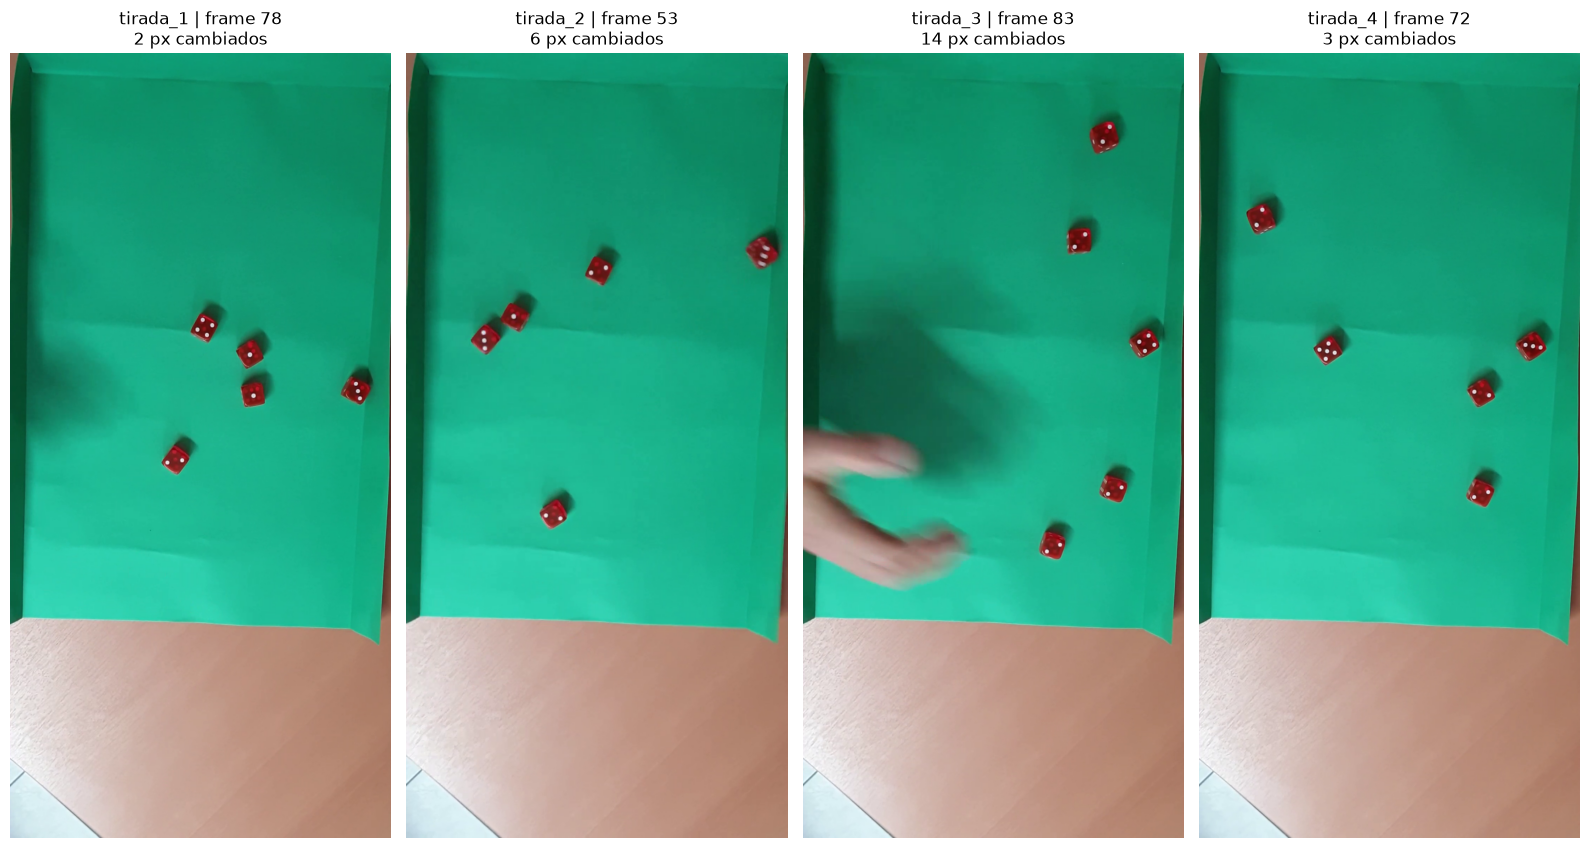

In [40]:
AREA_MIN = 1000   # ignora frames sin dados (mesa vacía) o con solo parte de ellos

def leer_frame(path, n_frame):
    cap = cv2.VideoCapture(path)
    cap.set(cv2.CAP_PROP_POS_FRAMES, n_frame)
    ok, frame = cap.read()
    cap.release()
    return frame

fig, axs = plt.subplots(1, 4, figsize=(16, 9))
for i, ax in zip(range(1, 5), axs):
    cambios, areas = resultados[i]

    # Frames candidatos: hay dados visibles. El frame 0 se excluye (su cambio es 0 por definición)
    candidatos = np.where(areas >= AREA_MIN)[0]
    candidatos = candidatos[candidatos > 0]

    mejor = candidatos[np.argmin(cambios[candidatos])]   # si hay empate, toma el primero
    print(f"tirada_{i}: frame {mejor} | px cambiados = {cambios[mejor]} | área roja = {areas[mejor]}")

    frame = leer_frame(f"tirada_{i}.mp4", mejor)
    ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    ax.set_title(f"tirada_{i} | frame {mejor}\n{cambios[mejor]} px cambiados")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [41]:
AREA_MIN = 1000      # área roja mínima para considerar que hay dados
VENTANA = 2          # para elegir el frame de referencia se promedia el cambio en ±2 frames
TOL = 5              # tolerancia (px de la imagen reducida) al comparar contra el frame quieto
UMBRAL = 0.05        # diferencia máxima con el frame quieto (fracción de su área roja)
KERNEL_TOL = np.ones((TOL, TOL), np.uint8)

def leer_mascaras(path):
    cap = cv2.VideoCapture(path)
    mascaras = []
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        frame = cv2.resize(frame, None, fx=ESCALA, fy=ESCALA, interpolation=cv2.INTER_AREA)
        mascaras.append(mascara_roja(frame))
    cap.release()
    return mascaras

def diferencia_tolerante(m, ref):
    """Píxeles rojos de m lejos de los de ref + píxeles rojos de ref sin rojo cerca en m."""
    nuevos   = cv2.countNonZero(cv2.bitwise_and(m, cv2.bitwise_not(cv2.dilate(ref, KERNEL_TOL))))
    perdidos = cv2.countNonZero(cv2.bitwise_and(ref, cv2.bitwise_not(cv2.dilate(m, KERNEL_TOL))))
    return nuevos + perdidos

def rango_quieto(mascaras):
    n = len(mascaras)
    areas = np.array([cv2.countNonZero(m) for m in mascaras])
    cambios = np.array([0] + [cv2.countNonZero(cv2.bitwise_xor(mascaras[k], mascaras[k-1]))
                              for k in range(1, n)])

    # 1) Frame de referencia: menor cambio promedio en una ventana, con dados visibles en toda ella
    prom = np.full(n, np.inf)
    for t in range(VENTANA + 1, n - VENTANA):
        if areas[t-VENTANA:t+VENTANA+1].min() >= AREA_MIN:
            prom[t] = cambios[t-VENTANA:t+VENTANA+1].mean()
    ref = int(np.argmin(prom))

    # 2) Diferencia de cada frame contra el de referencia (solo píxeles rojos)
    dif = np.array([diferencia_tolerante(m, mascaras[ref]) for m in mascaras]) / areas[ref]

    # 3) Se extiende hacia atrás y hacia adelante mientras la diferencia sea <= UMBRAL
    ini = ref
    while ini > 0 and dif[ini-1] <= UMBRAL:
        ini -= 1
    fin = ref
    while fin < n - 1 and dif[fin+1] <= UMBRAL:
        fin += 1
    return ref, ini, fin, dif

In [42]:
def generar_video(path_in, path_out, ini, fin, lado=120, margen=40):
    cap = cv2.VideoCapture(path_in)
    w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    out = cv2.VideoWriter(path_out, cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))

    n = 0
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        if ini <= n <= fin:   # cuadrado rojo arriba a la derecha
            cv2.rectangle(frame, (w - margen - lado, margen), (w - margen, margen + lado),
                          (0, 0, 255), -1)
        out.write(frame)
        n += 1
    cap.release()
    out.release()

In [43]:
rangos = {}
for i in range(1, 5):
    mascaras = leer_mascaras(f"tirada_{i}.mp4")
    ref, ini, fin, dif = rango_quieto(mascaras)
    rangos[i] = (ref, ini, fin, dif)
    print(f"tirada_{i}: referencia = frame {ref} | cuadrado rojo en frames {ini}-{fin} ({fin-ini+1} frames)")
    generar_video(f"tirada_{i}.mp4", f"salida_tirada_{i}.mp4", ini, fin)

tirada_1: referencia = frame 80 | cuadrado rojo en frames 63-88 (26 frames)
tirada_2: referencia = frame 69 | cuadrado rojo en frames 55-71 (17 frames)
tirada_3: referencia = frame 76 | cuadrado rojo en frames 63-87 (25 frames)
tirada_4: referencia = frame 57 | cuadrado rojo en frames 46-87 (42 frames)


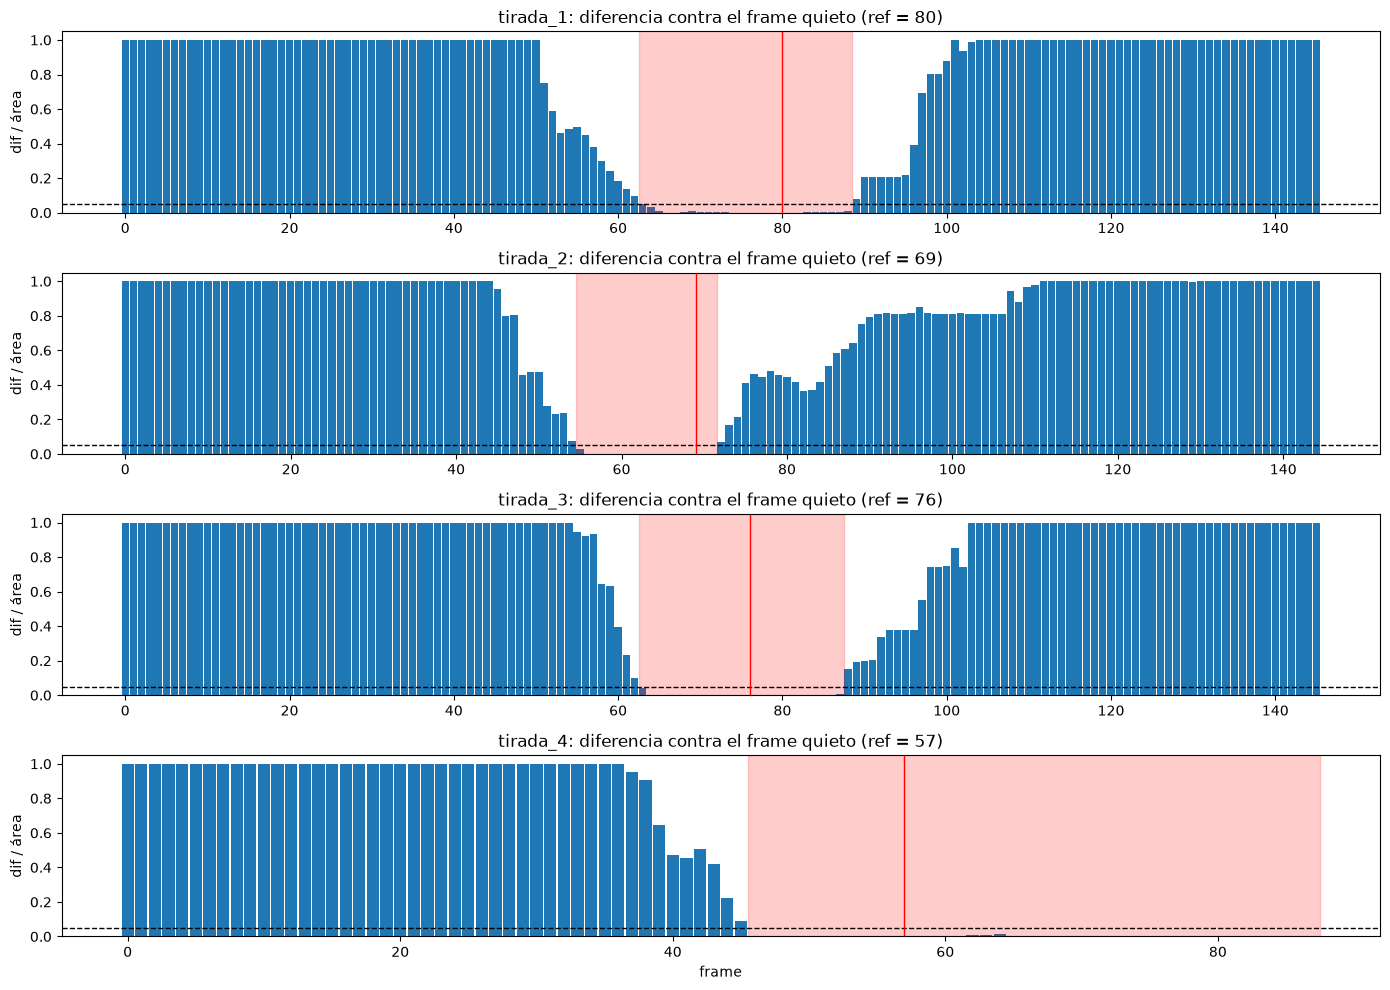

In [44]:
fig, axs = plt.subplots(4, 1, figsize=(14, 10))
for i, ax in zip(range(1, 5), axs):
    ref, ini, fin, dif = rangos[i]
    ax.bar(range(len(dif)), np.minimum(dif, 1.0), color="tab:blue", width=0.9)
    ax.axvspan(ini - 0.5, fin + 0.5, color="red", alpha=0.2)   # zona con cuadrado
    ax.axhline(UMBRAL, color="k", ls="--", lw=1)               # umbral
    ax.axvline(ref, color="red", lw=1)                         # frame de referencia
    ax.set_title(f"tirada_{i}: diferencia contra el frame quieto (ref = {ref})")
    ax.set_ylabel("dif / área")
axs[-1].set_xlabel("frame")
plt.tight_layout()
plt.show()

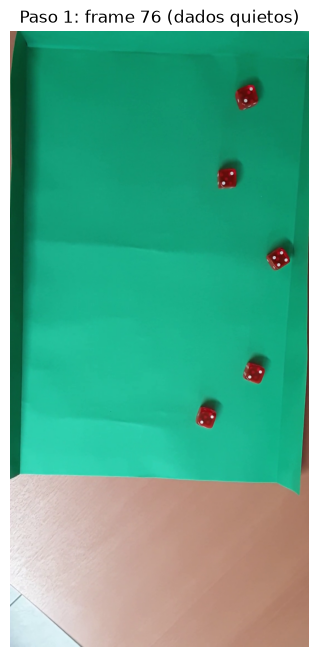

In [89]:
# Frame de referencia (dados quietos) de tirada_1
ref, ini, fin, dif = rango_quieto(MASCARAS[3])
frame = leer_frame("tirada_3.mp4", ref)

def mostrar(img, titulo, cmap=None):
    plt.figure(figsize=(8, 8))
    plt.imshow(img, cmap=cmap)
    plt.title(titulo)
    plt.axis("off")
    plt.show()

mostrar(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB), f"Paso 1: frame {ref} (dados quietos)")

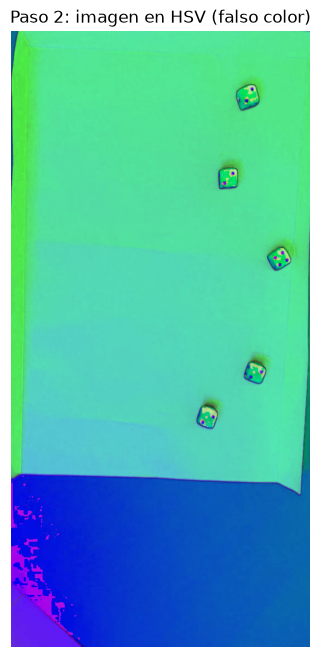

In [90]:
hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
mostrar(hsv, "Paso 2: imagen en HSV (falso color)")

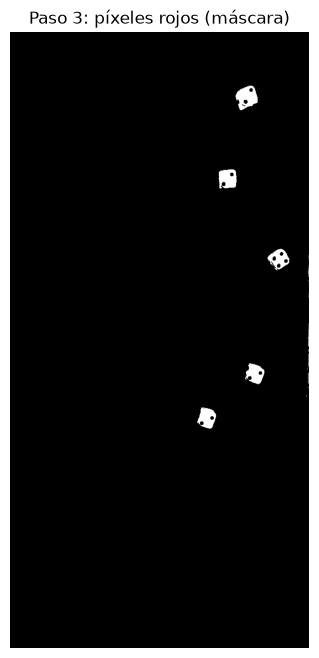

In [91]:
rojo_bajo = cv2.inRange(hsv, (0, S_MIN, V_MIN),   (10, 255, 255))
rojo_alto = cv2.inRange(hsv, (170, S_MIN, V_MIN), (180, 255, 255))
mascara = rojo_bajo | rojo_alto

mostrar(mascara, "Paso 3: píxeles rojos (máscara)", cmap="gray")

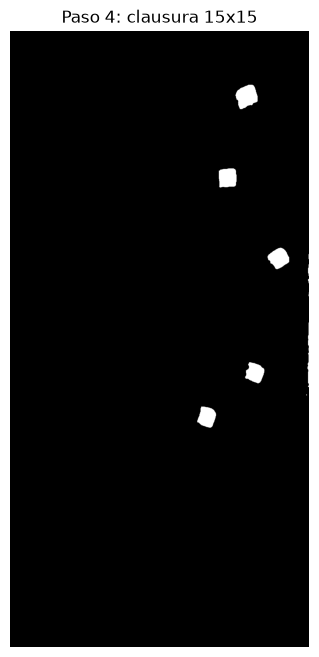

In [92]:
TAM_CIERRE = 15   # tiene que ser mayor que el diámetro de un punto, pero sin llegar a unir dados vecinos
kernel_cierre = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (TAM_CIERRE, TAM_CIERRE))
cerrada = cv2.morphologyEx(mascara, cv2.MORPH_CLOSE, kernel_cierre)

mostrar(cerrada, f"Paso 4: clausura {TAM_CIERRE}x{TAM_CIERRE}", cmap="gray")

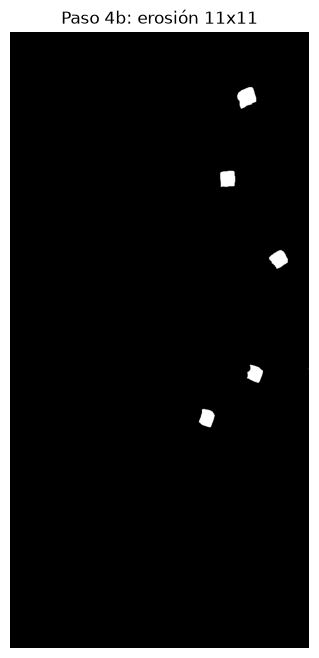

In [93]:
TAM_APERTURA = 11   # mayor que el grosor del ruido, pero bastante menor que el lado de un dado (~60 px)
kernel_apertura = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (TAM_APERTURA, TAM_APERTURA))

erosionada = cv2.erode(cerrada, kernel_apertura)
mostrar(erosionada, f"Paso 4b: erosión {TAM_APERTURA}x{TAM_APERTURA}", cmap="gray")

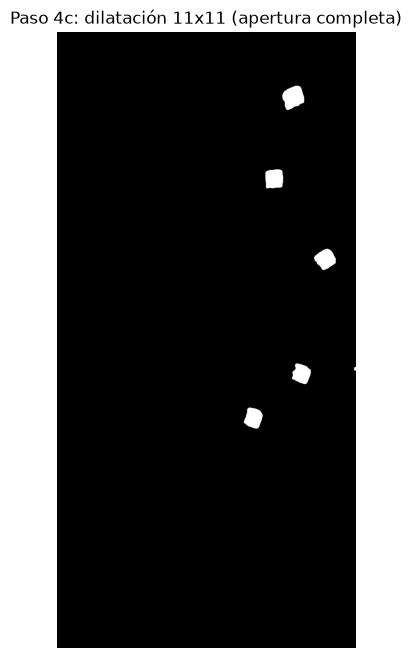

In [94]:
abierta = cv2.dilate(erosionada, kernel_apertura)   # mismo kernel que en la erosión
mostrar(abierta, f"Paso 4c: dilatación {TAM_APERTURA}x{TAM_APERTURA} (apertura completa)", cmap="gray")

comp  1 | área=  4944 | aspecto=0.91 | relleno=0.87 | DADO
comp  2 | área=  3990 | aspecto=0.95 | relleno=0.94 | DADO
comp  3 | área=  4006 | aspecto=0.94 | relleno=0.88 | DADO
comp  4 | área=  3625 | aspecto=1.00 | relleno=0.89 | DADO
comp  5 | área=    68 | aspecto=0.38 | relleno=1.05 | descartada
comp  6 | área=  3741 | aspecto=0.87 | relleno=0.89 | DADO

Componentes encontradas: 6 | aceptadas como dados: 5


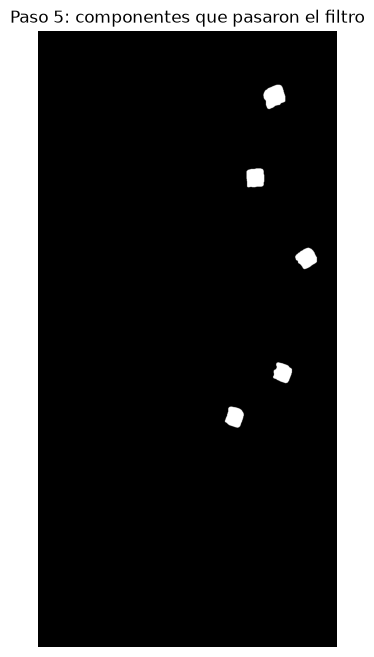

In [95]:
# Parámetros del filtro (puntos de partida estimados: ajustar mirando lo que imprime la celda)
AREA_MIN_DADO = 1500
AREA_MAX_DADO = 12000
ASPECTO_MIN = 0.75     # lado menor / lado mayor del rectángulo rotado (1 = cuadrado perfecto)
RELLENO_MIN = 0.80     # área / área del rectángulo rotado (1 = lo llena por completo)

n, etiquetas, stats, centroides = cv2.connectedComponentsWithStats(abierta, connectivity=8)

mascara_dados = np.zeros_like(cerrada)
dados = []
for k in range(1, n):   # la etiqueta 0 es el fondo
    area = stats[k, cv2.CC_STAT_AREA]
    comp = (etiquetas == k).astype(np.uint8) * 255
    pts = cv2.findNonZero(comp)
    (cx, cy), (rw, rh), ang = cv2.minAreaRect(pts)

    lado_menor, lado_mayor = min(rw, rh), max(rw, rh)
    aspecto = lado_menor / lado_mayor if lado_mayor > 0 else 0
    relleno = area / (rw * rh) if rw * rh > 0 else 0

    ok = (AREA_MIN_DADO <= area <= AREA_MAX_DADO) and aspecto >= ASPECTO_MIN and relleno >= RELLENO_MIN
    print(f"comp {k:2d} | área={area:6d} | aspecto={aspecto:.2f} | relleno={relleno:.2f} | {'DADO' if ok else 'descartada'}")

    if ok:
        mascara_dados[etiquetas == k] = 255
        dados.append({"etiqueta": k, "centro": (cx, cy), "area": area})

print(f"\nComponentes encontradas: {n-1} | aceptadas como dados: {len(dados)}")
mostrar(mascara_dados, "Paso 5: componentes que pasaron el filtro", cmap="gray")

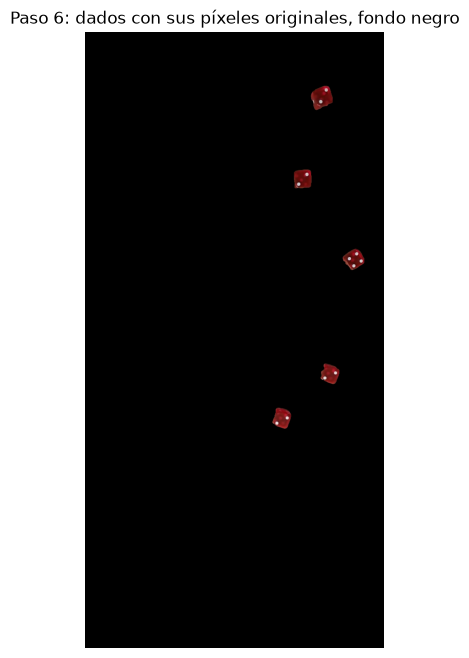

In [96]:
resultado = cv2.bitwise_and(frame, frame, mask=mascara_dados)   # fuera de la máscara queda negro
mostrar(cv2.cvtColor(resultado, cv2.COLOR_BGR2RGB), "Paso 6: dados con sus píxeles originales, fondo negro")

Dado 1: umbral de Otsu = 107
Dado 2: umbral de Otsu = 114
Dado 3: umbral de Otsu = 121
Dado 4: umbral de Otsu = 129
Dado 5: umbral de Otsu = 134


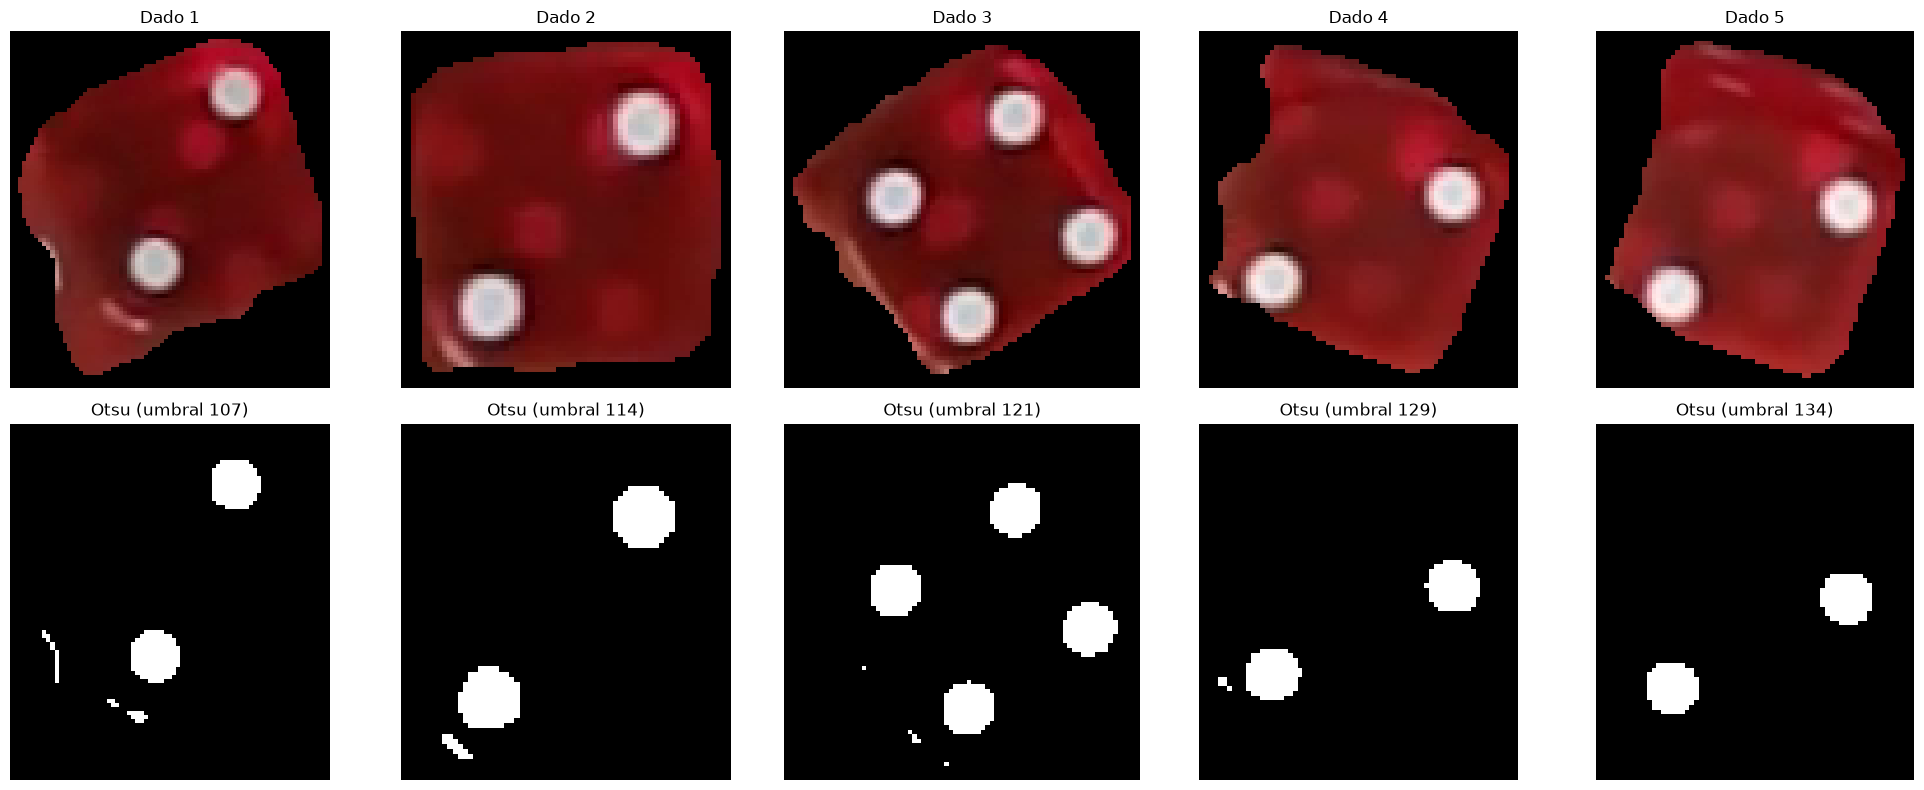

In [97]:
KERNEL_BORDE = np.ones((5, 5), np.uint8)   # para descartar el borde del dado (se mezcla con el fondo)
gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

fig, axs = plt.subplots(2, len(dados), figsize=(4 * len(dados), 8), squeeze=False)

for col, d in enumerate(dados):
    k = d["etiqueta"]
    mascara_dado = (etiquetas == k).astype(np.uint8) * 255
    mascara_interior = cv2.erode(mascara_dado, KERNEL_BORDE)

    # Recorte del dado (bounding box)
    x, y, w, h = cv2.boundingRect(mascara_dado)
    recorte_color = frame[y:y+h, x:x+w]
    recorte_gris = gris[y:y+h, x:x+w]
    recorte_mask = mascara_interior[y:y+h, x:x+w]

    # Otsu usando SOLO los píxeles del dado (el fondo negro no entra en el cálculo)
    valores = recorte_gris[recorte_mask > 0].reshape(-1, 1)
    umbral, _ = cv2.threshold(valores, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # Píxeles claros (candidatos a puntos) dentro del dado
    claros = ((recorte_gris > umbral) & (recorte_mask > 0)).astype(np.uint8) * 255

    # Guardo lo necesario para el siguiente paso (contar puntos)
    d["bbox"], d["claros"], d["umbral"] = (x, y, w, h), claros, umbral
    print(f"Dado {col+1}: umbral de Otsu = {umbral:.0f}")

    axs[0, col].imshow(cv2.cvtColor(recorte_color * (recorte_mask[..., None] > 0), cv2.COLOR_BGR2RGB))
    axs[0, col].set_title(f"Dado {col+1}")
    axs[1, col].imshow(claros, cmap="gray")
    axs[1, col].set_title(f"Otsu (umbral {umbral:.0f})")
    axs[0, col].axis("off"); axs[1, col].axis("off")

plt.tight_layout()
plt.show()

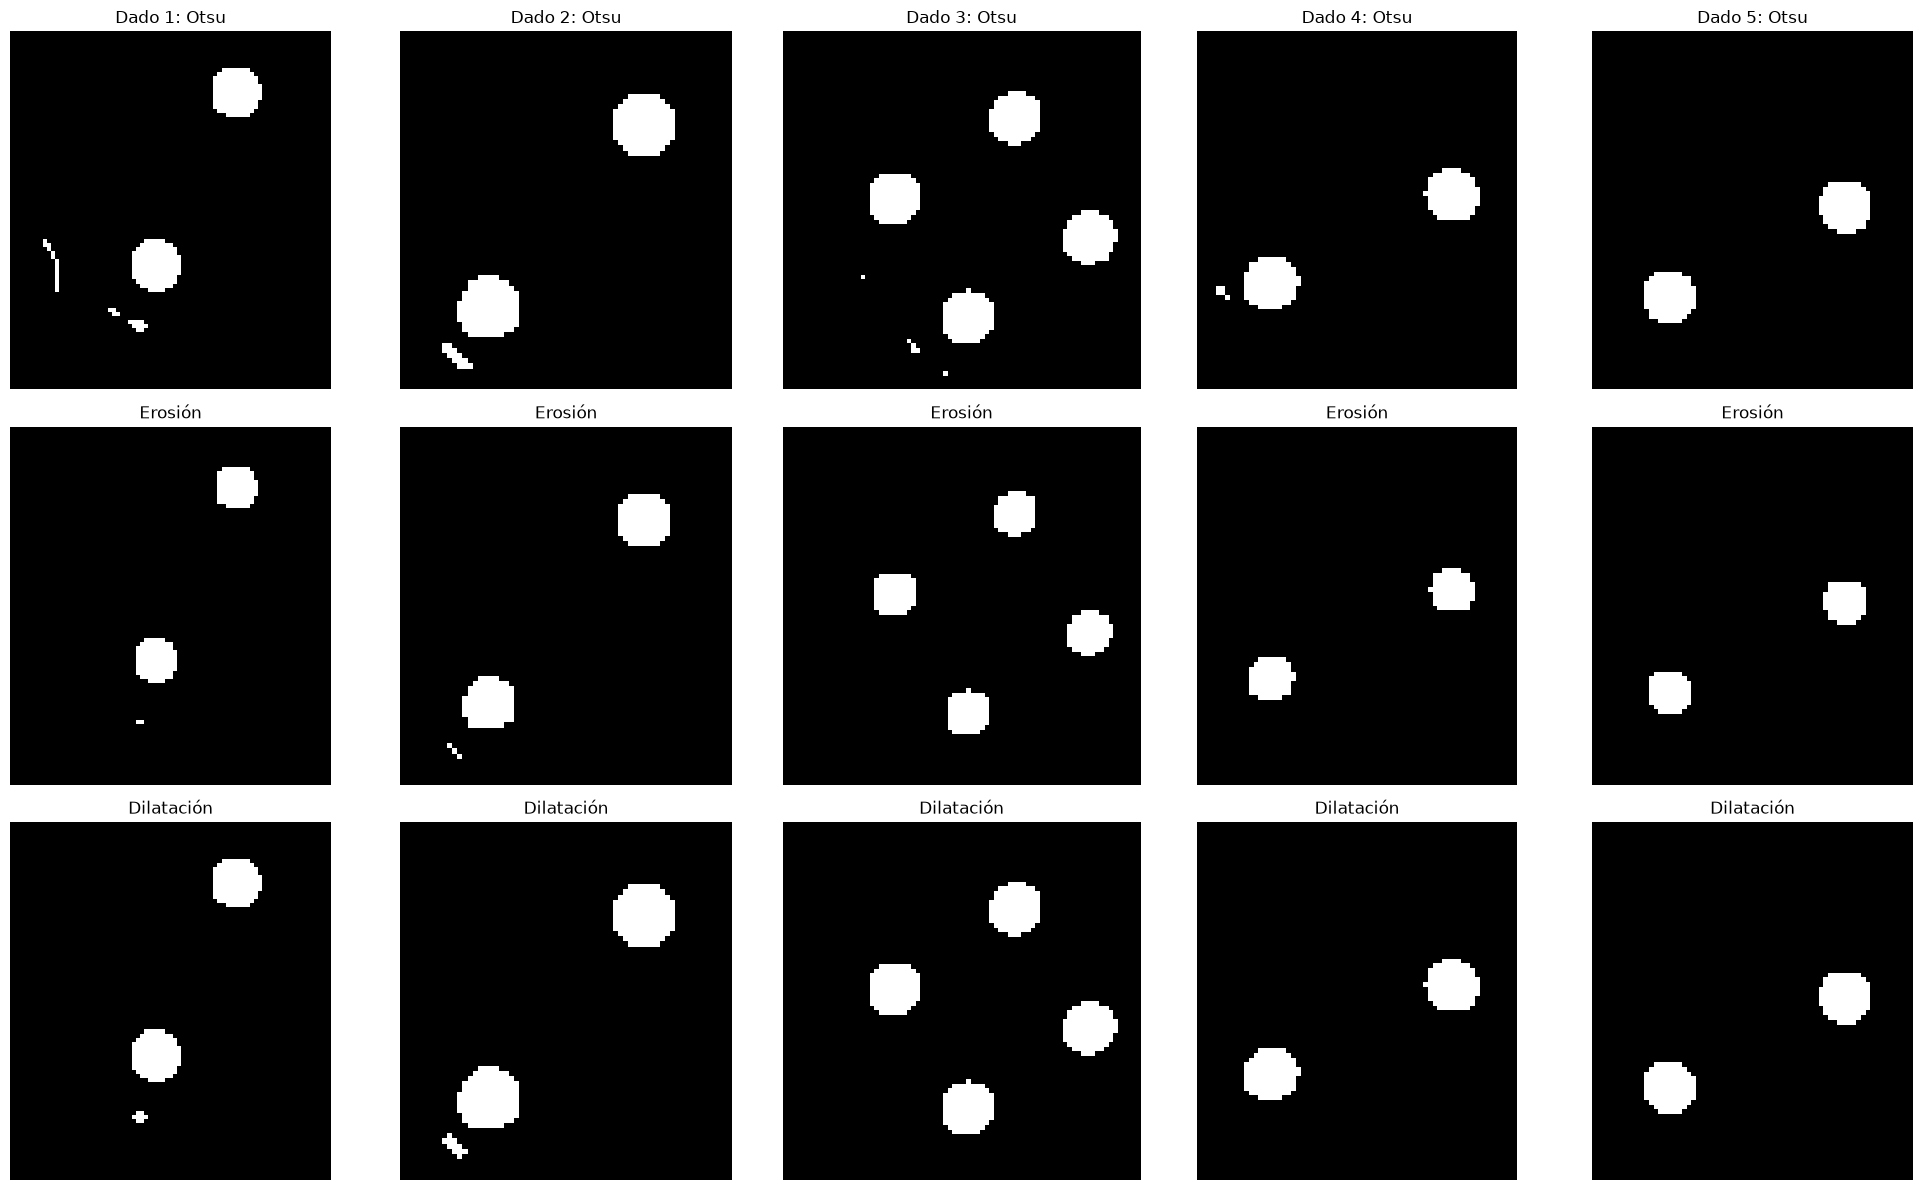

In [98]:
TAM_PUNTOS = 3   # kernel chico: tiene que ser bastante menor que el diámetro de un punto (~8-10 px)
kernel_puntos = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (TAM_PUNTOS, TAM_PUNTOS))

fig, axs = plt.subplots(3, len(dados), figsize=(4 * len(dados), 12), squeeze=False)
for col, d in enumerate(dados):
    erosionada = cv2.erode(d["claros"], kernel_puntos)
    dilatada = cv2.dilate(erosionada, kernel_puntos)
    d["puntos_bin"] = dilatada          # lo uso en la celda siguiente

    axs[0, col].imshow(d["claros"], cmap="gray");  axs[0, col].set_title(f"Dado {col+1}: Otsu")
    axs[1, col].imshow(erosionada, cmap="gray");   axs[1, col].set_title("Erosión")
    axs[2, col].imshow(dilatada, cmap="gray");     axs[2, col].set_title("Dilatación")
    for f in range(3):
        axs[f, col].axis("off")

plt.tight_layout()
plt.show()

--- Dado 1 ---
  blob 1: área= 123 | factor de forma=0.91 | PUNTO
  blob 2: área= 127 | factor de forma=0.90 | PUNTO
  blob 3: área=   8 | factor de forma=0.86 | descartado
Dado 1: 2 puntos
--- Dado 2 ---
  blob 1: área= 120 | factor de forma=0.95 | PUNTO
  blob 2: área= 118 | factor de forma=0.90 | PUNTO
  blob 3: área=  11 | factor de forma=0.59 | descartado
Dado 2: 2 puntos
--- Dado 3 ---
  blob 1: área= 106 | factor de forma=0.89 | PUNTO
  blob 2: área= 106 | factor de forma=0.93 | PUNTO
  blob 3: área= 109 | factor de forma=0.88 | PUNTO
  blob 4: área= 107 | factor de forma=0.90 | PUNTO
Dado 3: 4 puntos
--- Dado 4 ---
  blob 1: área= 103 | factor de forma=0.86 | PUNTO
  blob 2: área= 106 | factor de forma=0.89 | PUNTO
Dado 4: 2 puntos
--- Dado 5 ---
  blob 1: área= 100 | factor de forma=0.91 | PUNTO
  blob 2: área= 100 | factor de forma=0.94 | PUNTO
Dado 5: 2 puntos


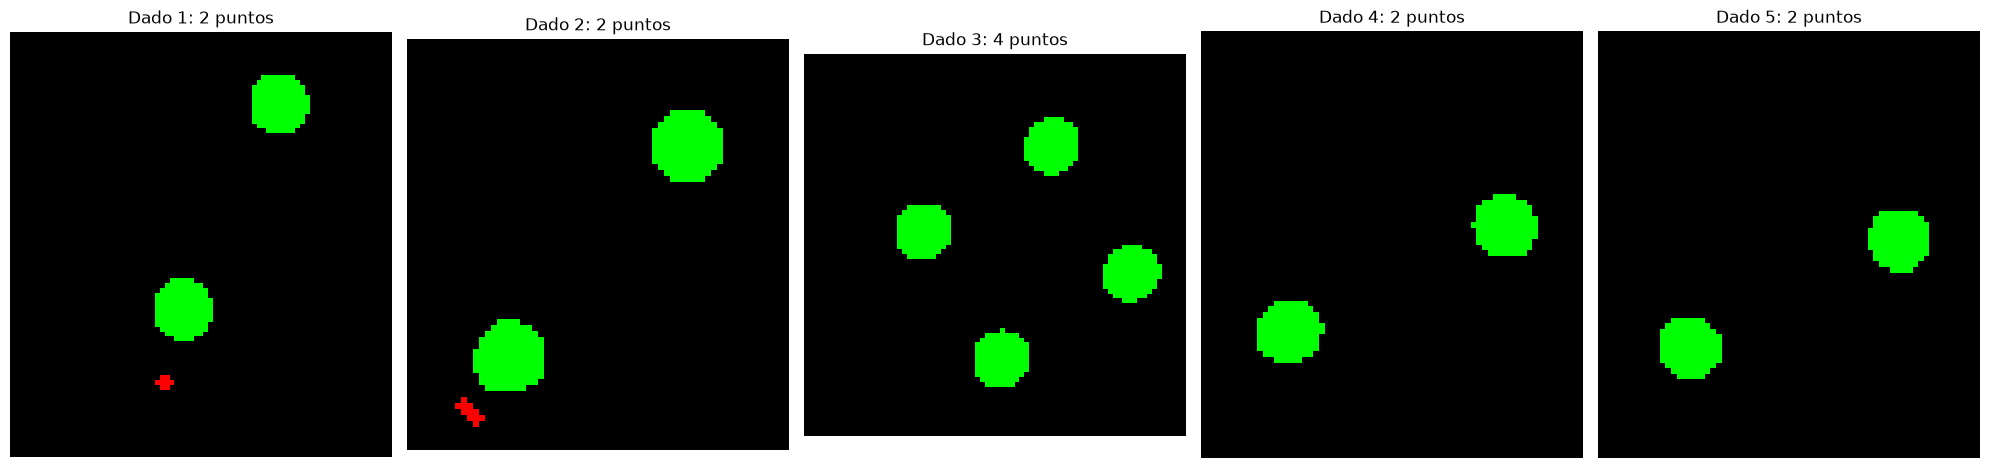


Valores de los dados: [2, 2, 4, 2, 2]


In [99]:
AREA_MIN_PUNTO = 20     # píxeles mínimos para ser un punto (descarta ruido)
AREA_MAX_PUNTO = 400    # píxeles máximos (descarta manchas grandes)
CIRC_MIN = 0.70         # factor de forma 4*pi*A / P^2 (1 = círculo perfecto)

fig, axs = plt.subplots(1, len(dados), figsize=(4 * len(dados), 5), squeeze=False)
for col, d in enumerate(dados):
    binaria = d["puntos_bin"]
    n_p, et_p, st_p, _ = cv2.connectedComponentsWithStats(binaria, connectivity=8)

    vis = cv2.cvtColor(binaria, cv2.COLOR_GRAY2RGB)   # verde = punto aceptado, rojo = descartado
    cantidad = 0
    print(f"--- Dado {col+1} ---")
    for k in range(1, n_p):
        area = st_p[k, cv2.CC_STAT_AREA]
        comp = (et_p == k).astype(np.uint8)
        contornos, _ = cv2.findContours(comp, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cnt = contornos[0]
        perimetro = cv2.arcLength(cnt, True)
        area_cnt = cv2.contourArea(cnt)               # área del contorno (consistente con el perímetro)
        circ = 4 * np.pi * area_cnt / perimetro**2 if perimetro > 0 else 0

        es_punto = (AREA_MIN_PUNTO <= area <= AREA_MAX_PUNTO) and circ >= CIRC_MIN
        vis[et_p == k] = (0, 255, 0) if es_punto else (255, 0, 0)
        cantidad += int(es_punto)
        print(f"  blob {k}: área={area:4d} | factor de forma={circ:.2f} | {'PUNTO' if es_punto else 'descartado'}")

    d["valor"] = cantidad
    print(f"Dado {col+1}: {cantidad} puntos")

    axs[0, col].imshow(vis)
    axs[0, col].set_title(f"Dado {col+1}: {cantidad} puntos")
    axs[0, col].axis("off")

plt.tight_layout()
plt.show()

print("\nValores de los dados:", [d["valor"] for d in dados])

In [100]:
# ---------- Parámetros: usá los valores que te funcionaron en las pruebas ----------
TAM_CIERRE, TAM_APERTURA = 15, 11
AREA_MIN_DADO, AREA_MAX_DADO = 1500, 12000
ASPECTO_MIN, RELLENO_MIN = 0.75, 0.80
TAM_BORDE = 5
TAM_PUNTOS = 3
AREA_MIN_PUNTO, AREA_MAX_PUNTO, CIRC_MIN = 20, 400, 0.70
PAD = 10   # margen al recortar cada dado

KERNEL_CIERRE   = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (TAM_CIERRE, TAM_CIERRE))
KERNEL_APERTURA = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (TAM_APERTURA, TAM_APERTURA))
KERNEL_BORDE    = np.ones((TAM_BORDE, TAM_BORDE), np.uint8)
KERNEL_PUNTOS   = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (TAM_PUNTOS, TAM_PUNTOS))


def contar_puntos(binaria):
    """Cuenta los blobs que son círculos (por tamaño y factor de forma)."""
    n, et, st, _ = cv2.connectedComponentsWithStats(binaria, connectivity=8)
    cantidad = 0
    for k in range(1, n):
        area = st[k, cv2.CC_STAT_AREA]
        if not (AREA_MIN_PUNTO <= area <= AREA_MAX_PUNTO):
            continue
        comp = (et == k).astype(np.uint8)
        contornos, _ = cv2.findContours(comp, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cnt = contornos[0]
        perimetro = cv2.arcLength(cnt, True)
        if perimetro == 0:
            continue
        circ = 4 * np.pi * cv2.contourArea(cnt) / perimetro**2
        if circ >= CIRC_MIN:
            cantidad += 1
    return cantidad


def detectar_dados(frame):
    """Devuelve una lista de dados con id, bbox y valor, para un frame con los dados quietos."""
    H, W = frame.shape[:2]
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    rojo = (cv2.inRange(hsv, (0, S_MIN, V_MIN), (10, 255, 255)) |
            cv2.inRange(hsv, (170, S_MIN, V_MIN), (180, 255, 255)))
    cerrada = cv2.morphologyEx(rojo, cv2.MORPH_CLOSE, KERNEL_CIERRE)        # rellena los puntos
    abierta = cv2.morphologyEx(cerrada, cv2.MORPH_OPEN, KERNEL_APERTURA)    # saca ruido
    n, et, stats, _ = cv2.connectedComponentsWithStats(abierta, connectivity=8)
    gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    dados = []
    for k in range(1, n):
        x, y, w, h, area = [int(v) for v in stats[k]]
        if not (AREA_MIN_DADO <= area <= AREA_MAX_DADO):
            continue

        # Recorte con margen alrededor del dado
        x0, y0 = max(x - PAD, 0), max(y - PAD, 0)
        x1, y1 = min(x + w + PAD, W), min(y + h + PAD, H)
        comp = (et[y0:y1, x0:x1] == k).astype(np.uint8) * 255

        # Filtro de forma: aproximadamente cuadrado
        (cx, cy), (rw, rh), _ = cv2.minAreaRect(cv2.findNonZero(comp))
        if rw * rh == 0:
            continue
        aspecto = min(rw, rh) / max(rw, rh)
        relleno = area / (rw * rh)
        if aspecto < ASPECTO_MIN or relleno < RELLENO_MIN:
            continue

        # Otsu solo con los píxeles del dado (sin el borde)
        interior = cv2.erode(comp, KERNEL_BORDE)
        recorte_gris = gris[y0:y1, x0:x1]
        valores = recorte_gris[interior > 0].reshape(-1, 1)
        if valores.size == 0:
            continue
        umbral, _ = cv2.threshold(valores, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        claros = ((recorte_gris > umbral) & (interior > 0)).astype(np.uint8) * 255
        claros = cv2.morphologyEx(claros, cv2.MORPH_OPEN, KERNEL_PUNTOS)    # erosión + dilatación

        dados.append({"bbox": (x, y, w, h),
                      "centro": (cx + x0, cy + y0),
                      "valor": contar_puntos(claros)})

    # Ids únicos: orden de lectura (arriba -> abajo, izquierda -> derecha)
    dados.sort(key=lambda d: (d["centro"][1], d["centro"][0]))
    for i, d in enumerate(dados, 1):
        d["id"] = i
    return dados

In [101]:
COLOR_CAJA = (0, 255, 255)   # amarillo (BGR): se ve bien sobre el verde y el rojo

def dibujar_dados(frame, dados):
    for d in dados:
        x, y, w, h = d["bbox"]
        cv2.rectangle(frame, (x, y), (x + w, y + h), COLOR_CAJA, 3)
        texto = f"D{d['id']}-{d['valor']}"
        pos_y = y - 12 if y > 45 else y + h + 38     # arriba de la caja (o abajo si no entra)
        cv2.putText(frame, texto, (x, pos_y), cv2.FONT_HERSHEY_SIMPLEX, 1.2, COLOR_CAJA, 3, cv2.LINE_AA)


def procesar_video(i):
    path_in = f"tirada_{i}.mp4"
    path_out = f"resultado_tirada_{i}.mp4"

    # A) Frames con los dados quietos
    mascaras = MASCARAS[i] if "MASCARAS" in globals() else leer_mascaras(path_in)
    ref, ini, fin, dif = rango_quieto(mascaras)

    # B) Valor de cada dado (se lee una sola vez, en el frame de referencia)
    dados = detectar_dados(leer_frame(path_in, ref))
    resumen = ", ".join(f"D{d['id']}-{d['valor']}" for d in dados)
    print(f"Tirada {i} | dados quietos en frames {ini}-{fin} | {resumen}")
    if len(dados) != 5:
        print(f"   ATENCIÓN: se detectaron {len(dados)} dados (se esperaban 5)")

    # C) Video resultante: cajas + ids + valores solo mientras están en reposo
    cap = cv2.VideoCapture(path_in)
    w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    out = cv2.VideoWriter(path_out, cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))

    n = 0
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        if ini <= n <= fin:
            dibujar_dados(frame, dados)
        out.write(frame)
        n += 1
    cap.release()
    out.release()
    return dados

In [102]:
resultados = {}
for i in range(1, 5):
    resultados[i] = procesar_video(i)

Tirada 1 | dados quietos en frames 63-88 | D1-4, D2-1, D3-3, D4-1, D5-2
Tirada 2 | dados quietos en frames 55-71 | D1-3, D2-2, D3-1, D4-3, D5-2
Tirada 3 | dados quietos en frames 63-87 | D1-2, D2-2, D3-4, D4-2, D5-2
Tirada 4 | dados quietos en frames 46-87 | D1-2, D2-3, D3-5, D4-2, D5-2
